# Model fitting with numpy and scipy
`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 20 Oct 2021

References: __[Scipy Cookbook #Fitting Data](https://scipy-cookbook.readthedocs.io/items/FittingData.html)__ ; *Numerical Recipes in C* §15

In [1]:
# import and settings
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as opt

In [2]:
# Generate synthetic measurements
a = 2.
b = 5.
sig0 = 4.
#
x = np.linspace(-10,10,200)
noise = np.random.normal(0., sig0, x.shape)
ymod = a * x + b
ymeas = ymod + noise
sig = sig0 * np.ones_like(x)
# check noise properties
print("mean(noise) = %.4f ; std(noise) = %.4f" % (np.mean(noise), np.std(noise)))

mean(noise) = -0.0113 ; std(noise) = 3.9023


In [3]:
# define the fit function and the error function
fitfunc = lambda x, a, b: a*x + b  # Target function

In [4]:
# define initial guess for the fit parameters anc compute corresponding model
p0 = [1., 0.]
y0 = fitfunc(x, *p0)
# perform fit
popt, pcov= opt.curve_fit(fitfunc, x, ymeas, sigma=sig, p0=p0, absolute_sigma=True, method='lm')
print(popt)
print(pcov)
# compute best-fit model
yopt = fitfunc(x, *popt)

[2.04317836 4.98866806]
[[ 2.37611942e-03 -8.23584048e-12]
 [-8.23584048e-12  7.99999986e-02]]


(-15.0, 15.0)

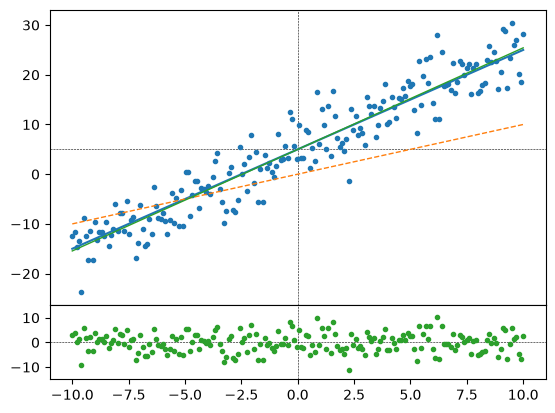

In [5]:
# plot data and model
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [4, 1]})
fig.subplots_adjust(hspace=0)
# main plot
ax1.axvline(0., ls='--', c='k', lw=0.4)
ax1.axhline(b, ls='--', c='k', lw=0.4)
ax1.plot(x, ymeas, marker='o', ms=3., color='tab:blue', ls='')
ax1.plot(x,ymod, c='tab:blue')
ax1.plot(x,y0, c='tab:orange', ls='--', lw=1.)
ax1.plot(x,yopt, c='tab:green', ls='-', lw=1.)
# residual 'O-C'
ax2.axhline(0., ls='--', c='k', lw=0.4)
ax2.axvline(0., ls='--', c='k', lw=0.4)
ax2.plot(x, ymeas-yopt, 'o', c='tab:green', ms=3.)
ax2.set_ylim(-15,15)
#plt.setp(ax1.get_xticklabels(), visible=False)

In [6]:
# reduced chi square
chisqr = lambda y1, y2, sig, nu: np.sum(((y1-y2)/sig)**2) / nu
nu = x.shape[0] - 2
chisqr_0 = chisqr(ymeas, y0, sig, nu)
chisqr_opt = chisqr(ymeas, yopt, sig, nu)
print("Initial reduced chi-square: %.3f" % chisqr_0)
print("Final reduced chi-square: %.3f" % chisqr_opt)
print("Degrees of freedom: %d" % nu)
print("Expected stdev on chisqr: %.3f" % (np.sqrt(2./float(nu))))

Initial reduced chi-square: 4.842
Final reduced chi-square: 0.957
Degrees of freedom: 198
Expected stdev on chisqr: 0.101


In [7]:
# compute uncertainties on parameters
sig_a = np.sqrt(pcov[0][0])
sig_b = np.sqrt(pcov[1][1])
print("a = %.3f ± %.3f" % (popt[0], sig_a))
print("b = %.3f ± %.3f" % (popt[1], sig_b))

a = 2.043 ± 0.049
b = 4.989 ± 0.283
